# Ising: Wolff cluster

In [22]:
import numpy as np
import torch
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(1)
torch.manual_seed(7)
SIZES = (4, 8, 16, 32, 64)
TEMPERATURES = np.array([1.6, 1.9, 2.05, 2.15, 2.22, 2.27, 2.32,
                         2.4, 2.5, 2.7, 3.0, 3.5, 4.0, 4.4])
ENSEMBLES, BURN, SAMPLES, STRIDE = 8, 2000, 800, 2
Tc = 2 / np.log(1 + np.sqrt(2))
print(f'PyTorch {torch.__version__} | {device}')

PyTorch 2.7.1+cu126 | cuda


In [23]:
try:
    from numba import njit
except ImportError:
    njit = None
if njit is not None:
    @njit
    def _seed(seed):
        np.random.seed(seed)
    @njit
    def _cpu_step(s, T):
        R, L, _ = s.shape
        p = 1-np.exp(-2/T)
        for r in range(R):
            y, x = np.random.randint(L), np.random.randint(L)
            spin = s[r, y, x]
            marked = np.zeros((L, L), dtype=np.bool_)
            ys, xs = np.empty(L*L, np.int32), np.empty(L*L, np.int32)
            marked[y, x] = True
            ys[0], xs[0] = y, x
            top = 1
            while top:
                top -= 1
                y, x = ys[top], xs[top]
                for k in range(4):
                    if k == 0:
                        ny, nx = (y+1)%L, x
                    elif k == 1:
                        ny, nx = (y-1+L)%L, x
                    elif k == 2:
                        ny, nx = y, (x+1)%L
                    else:
                        ny, nx = y, (x-1+L)%L
                    if not marked[ny, nx] and s[r, ny, nx] == spin and np.random.random() < p:
                        marked[ny, nx] = True
                        ys[top], xs[top] = ny, nx
                        top += 1
            for y in range(L):
                for x in range(L):
                    if marked[y, x]:
                        s[r, y, x] = -s[r, y, x]
    _seed(7)

def step(s, T):
    if device.type == 'cpu' and njit is not None:
        _cpu_step(s.numpy(), T)
        return s
    R, L, _ = s.shape
    sy = torch.randint(L, (R,), device=device)
    sx = torch.randint(L, (R,), device=device)
    root = torch.zeros_like(s, dtype=torch.bool)
    root[torch.arange(R, device=device), sy, sx] = True
    aligned = s == s[torch.arange(R, device=device), sy, sx][:, None, None]
    p = 1-np.exp(-2/T)
    right = (torch.rand(s.shape, device=device) < p) & (s == torch.roll(s, -1, -1))
    down = (torch.rand(s.shape, device=device) < p) & (s == torch.roll(s, -1, -2))
    cluster, frontier = root.clone(), root
    while bool(frontier.any()):
        nxt = ((torch.roll(frontier & right, 1, -1) |
                (torch.roll(frontier, -1, -1) & right) |
                torch.roll(frontier & down, 1, -2) |
                (torch.roll(frontier, -1, -2) & down)) & aligned & ~cluster)
        cluster |= nxt
        frontier = nxt
    s[cluster] *= -1
    return s

In [24]:
def observables(moments, L, T):
    mabs, m2, m4 = moments
    return np.array([L*L*(m2-mabs*mabs)/T, 1-m4/(3*m2*m2)])

def scan(sizes=SIZES, temperatures=TEMPERATURES, ensembles=ENSEMBLES,
         burn=BURN, samples=SAMPLES, stride=STRIDE):
    assert ensembles > 1 and all(L % 2 == 0 for L in sizes)
    values = np.empty((len(sizes), len(temperatures), 2))
    errors = np.empty_like(values)
    for i, L in enumerate(sizes):
        for j, T in enumerate(temperatures):
            s = (2*torch.randint(0, 2, (ensembles, L, L), device=device)-1).to(torch.int8)
            for _ in range(burn):
                step(s, float(T))
            moments = torch.zeros((ensembles, 3), device=device)
            for _ in range(samples):
                for _ in range(stride):
                    step(s, float(T))
                m = s.float().mean((-2, -1))
                m2 = m.square()
                moments += torch.stack((m.abs(), m2, m2.square()), 1)
            moments = (moments/samples).cpu().numpy()
            values[i, j] = observables(moments.mean(0), L, T)
            leave_one_out = (moments.sum(0)-moments)/(ensembles-1)
            jk = np.array([observables(x, L, T) for x in leave_one_out])
            errors[i, j] = np.sqrt((ensembles-1)/ensembles *
                                    ((jk-jk.mean(0))**2).sum(0))
    return values, errors

values, errors = scan()

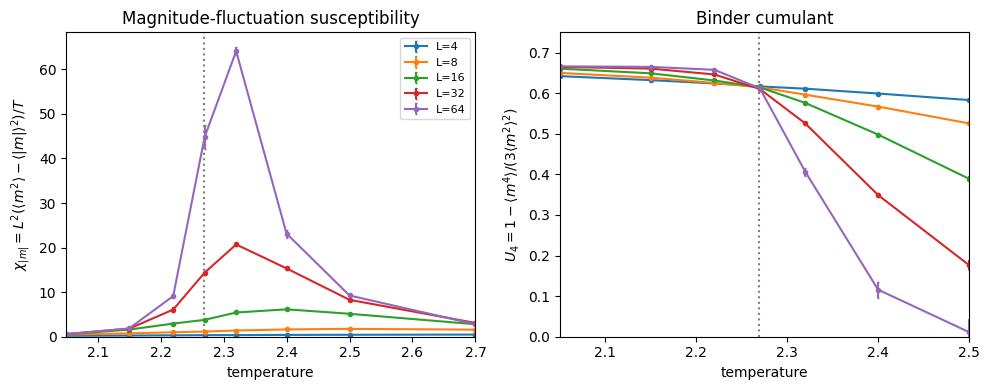

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
labels = [r'$\chi_{|m|}=L^2(\langle m^2\rangle-\langle|m|\rangle^2)/T$',
          r'$U_4=1-\langle m^4\rangle/(3\langle m^2\rangle^2)$']
for i, L in enumerate(SIZES):
    for k in range(2):
        ax[k].errorbar(TEMPERATURES, values[i, :, k], yerr=errors[i, :, k],
                       marker='o', ms=3, capsize=1, label=f'L={L}')
for a, label in zip(ax, labels):
    a.axvline(Tc, color='gray', ls=':')
    a.set(xlabel='temperature', ylabel=label)
ax[0].set(title='Magnitude-fluctuation susceptibility', xlim=(2.05, 2.7), ylim=(0, None))
ax[1].set(title='Binder cumulant', xlim=(2.05, 2.5), ylim=(0, .75))
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()